# Step 4: detection of LIN28A, TTYH1 and NES (annotated version)

Question 1 asks where the three genes are **co-expressed**. Before looking at all three together (step 05), we
look at each gene on its own: in which cell types, at which ages and with which kit is it detected?

**Definition used everywhere:** a gene is *expressed* (detected) in a cell when the cell has **at least 1 UMI**
of it, i.e. at least one RNA molecule of that gene was caught.

This notebook does two things:

1. Reads the counts of the three genes for all 1,665,937 cells and saves them, so step 05 never has to open the
   12 GB file again.
2. Shows, as a heatmap, the % of cells that express each gene per cell class, age bin and kit.

Output for step 05: `data/processed/gene_counts.csv.gz`. Figure: `results/figures/04_gene_detection.png`

*The figure shown is from the run of 13 November 2026 on the full dataset. Running the notebook again
overwrites it with an identical one.*

## Setup

**What this cell does**

- Same first lines as every notebook: move to the repository root and allow imports from `src/`.
- **pandas** is new here: the gene counts are kept as a table with cell names as rows.
- From `common.py`:
  - `B`: dataset settings, used for the gene symbol column
  - `BINS`: early, mid, late
  - `CFG`: the config, used for `chunk_size` and `min_cells`
  - `GENES`: LIN28A, TTYH1, NES
  - `PROCESSED`: the folder `data/processed/`, where files for the next step go
- `MIN_CELLS = 50` (from `config.yaml`): a percentage based on very few cells is unreliable. Groups with fewer
  than 50 cells are left empty in the heatmap.

In [1]:
# The notebooks live in notebooks/. Move to the repository root so config.yaml, data/ and results/
# are found, and make src/common.py importable.
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import B, BINS, CFG, GENES, PROCESSED, cell_table, open_braun, save

MIN_CELLS = CFG["min_cells"]  # groups with fewer cells than this are left empty in the heatmap

## Load the data

**What this cell does**

Opens the h5ad without loading the matrix (`open_braun`) and builds the per-cell table (`cell_table`). We need
the table for the cell class, age bin and kit of every cell.

In [2]:
adata = open_braun()
cells = cell_table(adata)

## Read the three genes for every cell

**Why read in blocks:** the matrix is stored cell by cell
(one row per cell). Reading one column (one gene) for all cells would still mean going through every row. So
we walk through the cells in blocks and, from each block, keep only our three columns.

**What this cell does**

- `gene_cols`: the column number of each gene.
  - `adata.var[B["symbol_col"]] == g` gives True for the gene whose symbol is `g` and False for all others
  - `np.flatnonzero(...)` returns the positions of the True values; `[0]` takes the first (and only) one.
    Step 03 already confirmed each gene is present exactly once.
- `blocks = []`: an empty list that collects the result of each block.
- The loop, for every block of `chunk_size` (20,000) cells:
  - `adata.X[start:start + chunk]` reads the block from disk (sparse: only non-zero counts stored)
  - `[:, gene_cols]` keeps only the three gene columns
  - `.toarray()` turns the small sparse block into a normal array (20,000 x 3), which is easy to stack
- `np.vstack(blocks)` stacks all blocks on top of each other: 1,665,937 rows x 3 columns.
- `.astype(int)`: the counts are whole numbers (step 03), so they are stored as integers.
- `pd.DataFrame(..., index=adata.obs_names, columns=GENES)`: a table with the cell names as row labels and the
  gene names as column labels, so later steps can match each row to its cell.
- `counts.to_csv(PROCESSED / "gene_counts.csv.gz")`: saves it. The `.gz` ending makes pandas compress the
  file, so it is about 10 MB instead of 12 GB. This file is the input of step 05.

This cell prints nothing; it takes a few minutes because it reads the whole matrix once.

In [3]:
# The matrix is stored cell by cell, so read blocks of cells and keep only our three columns.
# The result is small (1.67 million cells x 3 genes) and is saved for step 5.
gene_cols = [np.flatnonzero(adata.var[B["symbol_col"]] == g)[0] for g in GENES]
blocks = []
for start in range(0, adata.n_obs, CFG["chunk_size"]):
    blocks.append(adata.X[start:start + CFG["chunk_size"]][:, gene_cols].toarray())
counts = pd.DataFrame(np.vstack(blocks).astype(int), index=adata.obs_names, columns=GENES)
counts.to_csv(PROCESSED / "gene_counts.csv.gz")

**Result:** `data/processed/gene_counts.csv.gz`, 1,665,937 cells x 3 genes. Summed over all cells the
file holds 6,329 UMIs of LIN28A, 4,512,792 of TTYH1 and 1,427,731 of NES. LIN28A is very rare compared with
the other two, which already tells us it will limit co-expression.

## Detection per cell class, age bin and kit

**What this cell does**

- `expressed = counts >= 1`: turns every count into True (at least 1 UMI, expressed) or False (0 UMIs). This is
  the definition of expression, applied to all cells and the three genes at once.
- `groups = expressed.groupby([cell_class, age_bin, chemistry])`: puts the cells into groups, one per
  combination, e.g. Radial glia, early, v3.
- `percent = groups.mean() * 100`: the mean of True/False values is the share of True. Python counts True as 1
  and False as 0, so the mean of [True, False, False, True] is 2/4 = 0.5, i.e. 50% of cells express the gene.
  This gives the % of expressing cells for every group and gene.
- `size = groups.size()`: the number of cells in every group, used to hide groups that are too small.

**Why split by kit:** v3 catches more molecules per cell (step 02), so it detects every gene in more cells.
Mixing v2 and v3 cells would make a group look different only because of its kit mix.

In [4]:
# % of cells with >= 1 UMI for each gene, per cell class x age bin x kit
expressed = counts >= 1
groups = expressed.groupby([cells["cell_class"], cells["age_bin"], cells["chemistry"]])
percent = groups.mean() * 100
size = groups.size()

## Figure: detection heatmap

**Layout:** two panels, v2 on the left and v3 on the right. In each
panel the rows are the 12 cell classes and the 9 columns are gene x age bin (LIN28A early, mid, late, then TTYH1,
then NES). Each square shows the % of cells with at least 1 UMI; darker blue means higher.

**What this cell does**

- `classes`: the cell classes in alphabetical order, so both panels have the same rows.
- `columns`: the 9 (gene, age bin) pairs in order.
- `plt.subplots(1, 2, sharey=True)`: two panels side by side sharing the row labels.
- For each kit:
  - `grid = np.full(..., np.nan)`: a 12 x 9 table filled with NaN (empty). NaN squares are drawn blank.
  - the two inner loops fill in each square, but only if the group has at least `MIN_CELLS` cells.
    `size.get((c, b, kit), 0)` returns 0 when a combination does not exist at all (e.g. no Oligo cells early),
    instead of raising an error.
  - `ax.imshow(grid, cmap="Blues", vmin=0, vmax=100)` draws the table as coloured squares. Fixing the colour
    scale to 0 to 100 makes both panels directly comparable.
  - `np.ndenumerate(grid)` goes over every square with its position; `ax.text` writes the rounded % in it,
    white on dark squares (above 50) and black on light ones, so it stays readable.
  - the gene names are written above the middle of their three columns (`k * 3 + 1`).
- `fig.suptitle(...)` adds the legend line under the figure: what the numbers mean and the age bin ranges.
- `save(...)` writes the PNG and shows it here.

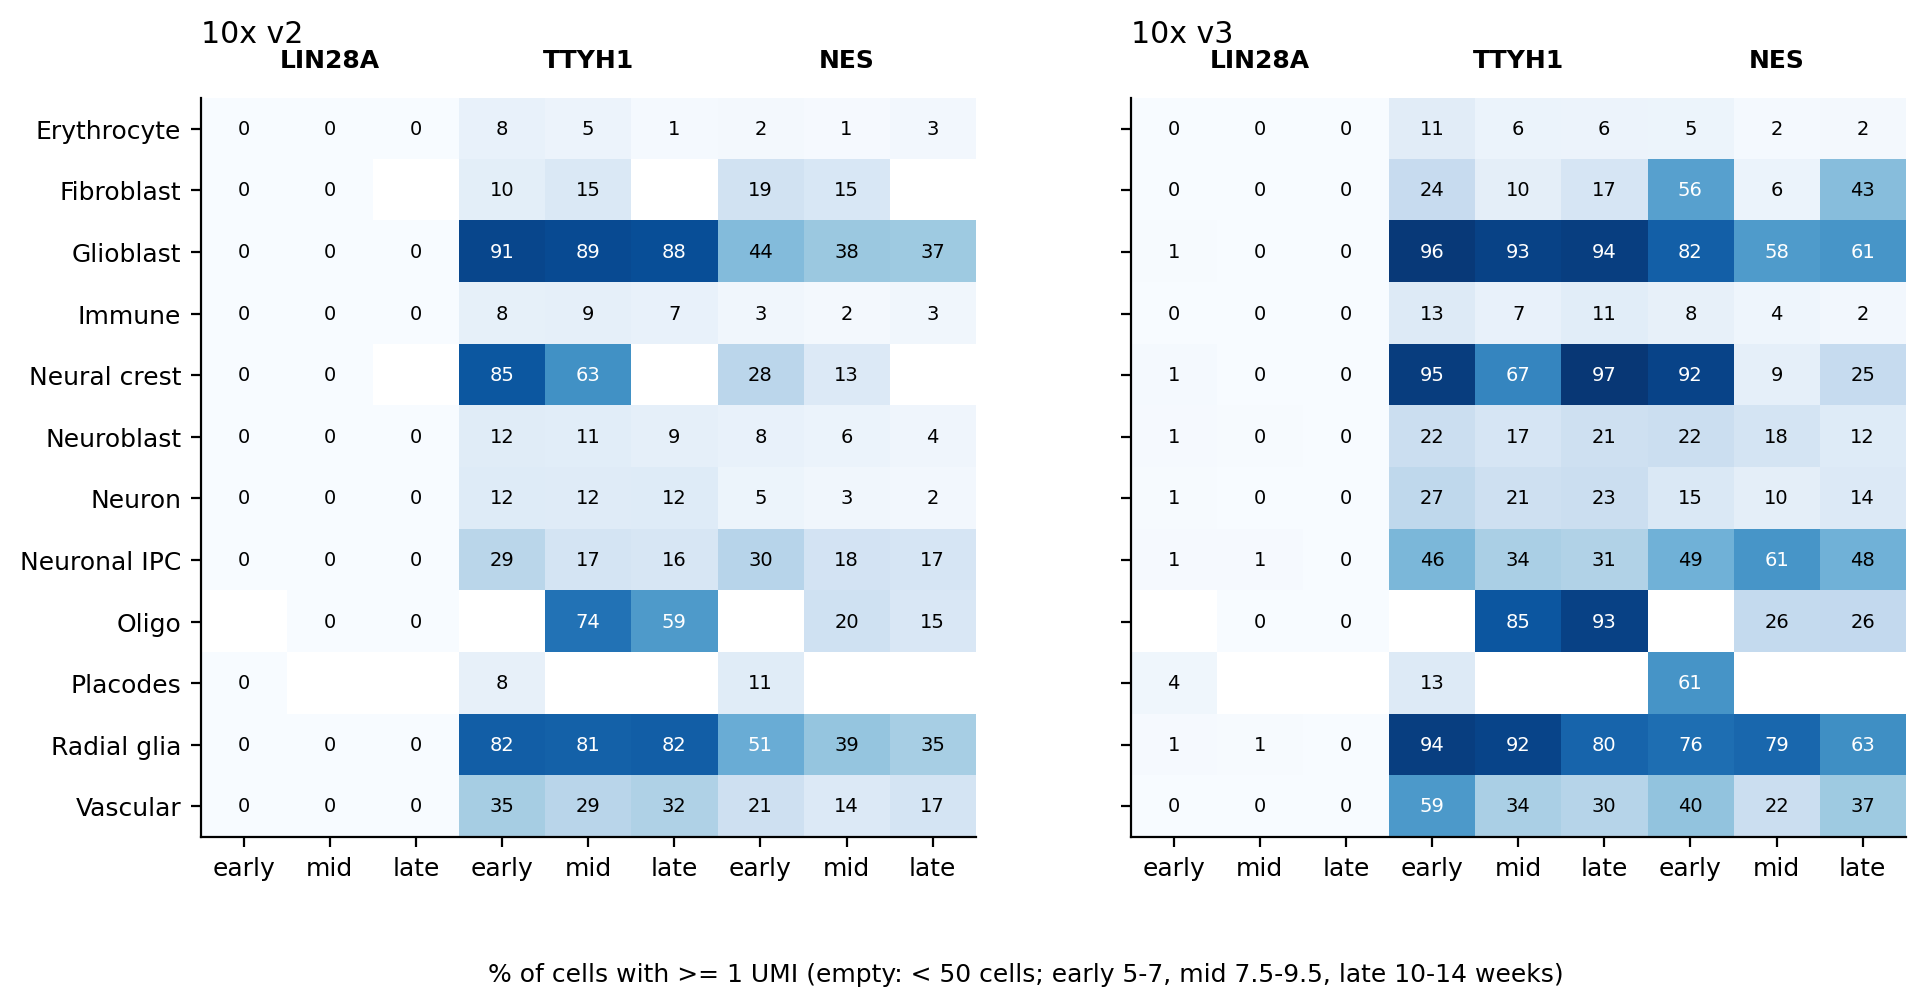

In [5]:
# Heatmap: one panel per kit (they are not directly comparable), rows = cell classes,
# columns = gene x age bin. Each cell of the heatmap shows the percentage as text.
classes = sorted(cells["cell_class"].unique())
columns = [(g, b) for g in GENES for b in BINS]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, kit in zip(axes, ["v2", "v3"]):
    grid = np.full((len(classes), len(columns)), np.nan)  # NaN = too few cells, drawn empty
    for i, c in enumerate(classes):
        for j, (g, b) in enumerate(columns):
            if size.get((c, b, kit), 0) >= MIN_CELLS:
                grid[i, j] = percent.loc[(c, b, kit), g]
    ax.imshow(grid, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    for (i, j), v in np.ndenumerate(grid):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 50 else "black")
    ax.set_xticks(range(len(columns)), [b for _, b in columns])
    for k, g in enumerate(GENES):  # gene name above its three age-bin columns
        ax.text(k * 3 + 1, -1, g, ha="center", fontweight="bold")
    ax.set_title(f"10x {kit}", loc="left", pad=20)
axes[0].set_yticks(range(len(classes)), classes)
fig.suptitle(f"% of cells with >= 1 UMI (empty: < {MIN_CELLS} cells; early 5-7, mid 7.5-9.5, late 10-14 weeks)",
             y=-0.02, fontsize=9)
save(fig, "04_gene_detection")

**Reading the figure**

- **LIN28A is rare everywhere.** In v2 it rounds to 0% in every group. In v3 it reaches 1% in radial glia,
  glioblasts, neural crest and several neuronal groups. Early placodes (a small group) reach 4%. By the late
  bin it is 0% in every class. LIN28A is a gene of very early development, so this fits biology: it is
  switched off as the brain matures.
- **TTYH1 is common in progenitors and glia.** Radial glia 80 to 94%, glioblasts 88 to 96%, neural crest 63 to
  97%, oligodendrocyte lineage 59 to 93%. Low in neurons, blood and immune cells (under 30%).
- **NES (nestin, a classic neural stem cell marker) is moderate.** Highest in radial glia (35 to 51% with v2,
  63 to 79% with v3), glioblasts, early neural crest (92% with v3) and neuronal intermediate progenitors.
- **v3 detects more in almost every square.** For example, NES in early radial glia: 51% with v2 against 76%
  with v3. Same cells, different kit. This confirms why kits are never pooled for detection rates.

## Conclusion of step 04

1. TTYH1 and NES are both common in radial glia and glioblasts, so many progenitor cells express two of the
   three genes.
2. LIN28A is the bottleneck: at most a few % of cells express it, only in early ages. Triple-positive cells
   can therefore only be rare and mostly early.
3. The likely places for co-expression are early radial glia, glioblasts, neural crest and neuronal
   intermediate progenitors. Step 05 tests this directly, cell by cell, against what chance would give.
4. Detection rates are kit-specific. Step 05 therefore ranks cell types on v3 cells only.